# Gene-wise variance concordance across all datasets

Compare Raw, SPLIT, ResolVI, ovrlpy (VSI <0.7), CellAdmix where available, and Syndri against the scRNA-seq reference across all four datasets. Matrix sources match the main, **unfiltered** metrics in `eval/AllDatasetMetricsSimplified.ipynb`.

Syndri uses **hard zeroing** and the per-slice settings from `results/metrics/syndri_zero_20261017_224620/unfiltered/non_tcell/`, with target fractions 0.1 (aging brain), 0.3 (brain), and 0.5 (CosMx/Xenium), a 0.5 probability floor, and the configured cell-type grouping. Aging brain uses milestone 87 predictions on regenerated inputs. Competitor file paths and layers are read from the same metric configuration directories as the metrics notebook, including the saved-model ResolVI exports. Missing competitor results remain missing.

Spatial matrices are normalized to 10,000 counts and log-transformed on the full gene panel before selecting reference-overlapping genes. This analysis retains its reference matching, cell-type minimum sizes, and gene detection criteria; it is a variance analysis, rather than a recomputation of the separation metrics. `matrix_sources_df` records the files and layers used. Old outputs were cleared for recomputation.

Only slices with a completed hard-zero metric run are evaluated; coverage is printed before computation. Rerunning after additional metric jobs finish includes those slices automatically.


In [1]:
from pathlib import Path
from types import SimpleNamespace
import json
import sys

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
from scipy.stats import spearmanr, wilcoxon
import matplotlib.font_manager as fm
import matplotlib as mpl

# Path to where you saved the downloaded Arial file
font_path = '/home/jwinchel/fonts/ARIAL.TTF'  
fm.fontManager.addfont(font_path)
mpl.rcParams['svg.fonttype'] = 'none'
# Set Arial globally
plt.rcParams['font.family'] = 'Arial'
REPO = Path('/home/jwinchel/Syndri')
FIGURE_DIR = REPO / 'figures' / 'outputs'

PROJECT = Path('/home/jwinchel/Syndri')
ROOT = Path('/work/magroup/skrieger/Syndri/data/datasets')
SYNDRI_METRICS_RUN = 'syndri_zero_20261017_224620'
AGINGBRAIN_RUN = '10x_agingbrain_donors5to8_m87_regenerated_rctd_20261010'
AGINGBRAIN_RESULTS = ROOT / 'agingbrain_merfish/results'
sys.path.insert(0, str(PROJECT / 'eval'))
from metrics_eval import cleaned_counts_for_removed_fraction_maybe_grouped

# Keep these selections in sync with eval/AllDatasetMetricsSimplified.ipynb.
DATASET_TITLES = {
    # 'agingbrain_merfish': 'Aging brain MERFISH',
    'brain_merfish': 'Brain MERFISH',
    'nsclc_cosmx': 'NSCLC CosMx',
    'breast_xenium': 'Breast Xenium',
}
SYNDRI_TARGET_FRACTIONS = {
    # 'agingbrain_merfish': 0.10,
    'brain_merfish': 0.30,
    'nsclc_cosmx': 0.50,
    'breast_xenium': 0.50,
}
REFERENCE_LABEL_KEYS = {
    # 'agingbrain_merfish': 'cell_type',
    'brain_merfish': 'class',
    'nsclc_cosmx': 'cell_type',
    'breast_xenium': 'cell_type',
}
BREAST_REFERENCE = ROOT / 'breast_xenium/interim/single-cell/breast_cancer_chromium_genesubset.h5ad'
# Metric directories identify the exact input file and layer used per method.
COMPETITOR_METRICS = {
    'ResolVI': 'resolvi',
    'ovrlpy': 'ovrlpy_pixel_correction/vsi_lt_0_7',
    'CellAdmix': 'celladmix_k1p5ct',
}
MIN_ST_CELLS = 50
MIN_SC_CELLS = 50
MIN_REF_DETECTION = 0.05

slice_paths = {
    dataset: sorted((
        AGINGBRAIN_RESULTS / 'model_runs' / AGINGBRAIN_RUN
        if dataset == 'agingbrain_merfish' else ROOT / dataset / 'results/final'
    ).glob('*.h5ad'))
    for dataset in DATASET_TITLES
}
if any(not paths for paths in slice_paths.values()):
    raise FileNotFoundError('At least one dataset has no final slice files')
print({dataset: len(paths) for dataset, paths in slice_paths.items()})
# Match the metrics notebook's completed hard-zero slice coverage.
for dataset, paths in slice_paths.items():
    metric_root = (ROOT / dataset / 'results/metrics' / SYNDRI_METRICS_RUN
                   / 'unfiltered/non_tcell')
    completed = [path for path in paths
                 if (metric_root / path.stem / 'complete.json').is_file()]
    print(f'{dataset}: {len(completed)}/{len(paths)} completed hard-zero slices')
    slice_paths[dataset] = completed
if not any(slice_paths.values()):
    raise FileNotFoundError('No completed hard-zero metric slices are available')


{'brain_merfish': 3, 'nsclc_cosmx': 8, 'breast_xenium': 19}
brain_merfish: 3/3 completed hard-zero slices
nsclc_cosmx: 8/8 completed hard-zero slices
breast_xenium: 19/19 completed hard-zero slices


In [3]:
def to_csr(X):
    if sp.issparse(X):
        return X.tocsr().astype(np.float32)
    return sp.csr_matrix(np.asarray(X, dtype=np.float32))


def normalize_log1p(X, target_sum=1e4):
    X = to_csr(X).copy()
    totals = np.asarray(X.sum(axis=1)).ravel()
    scale = np.divide(target_sum, totals, out=np.zeros_like(totals, dtype=np.float32), where=totals > 0)
    X = sp.diags(scale) @ X
    X.data = np.log1p(X.data)
    return X.tocsr()


def sparse_gene_variance(X):
    X = to_csr(X)
    mean = np.asarray(X.mean(axis=0)).ravel()
    mean_sq = np.asarray(X.power(2).mean(axis=0)).ravel()
    return np.maximum(mean_sq - mean**2, 0)


def metric_config(dataset, slice_path):
    metrics_root = (ROOT / dataset / 'results/metrics' / SYNDRI_METRICS_RUN
                    / 'unfiltered/non_tcell')
    path = metrics_root / slice_path.stem / 'non_tcell_metrics_config.json'
    if not path.exists():
        raise FileNotFoundError(f'Missing metric settings: {path}')
    config = json.loads(path.read_text())
    if len(config['input_files']) != 1 or Path(config['input_files'][0]) != slice_path:
        raise ValueError(f'{path}: metric input does not match {slice_path}')
    expected = {
        'cleaning_mode': 'zero',
        'cell_type_specific_removal': True,
        'probability_transform': 'power',
        'probability_power': 2.0,
        'clean_prob_threshold': 0.5,
        'library_size_target_sum': 10000.0,
    }
    for key, value in expected.items():
        if config.get(key) != value:
            raise ValueError(f'{path}: {key}={config.get(key)!r}; expected {value!r}')
    if config.get('sample_frac') != 1.0:
        raise ValueError(f'{path}: sampled metrics need an explicitly matched cell subset')
    if config.get('separation_min_counts', 0) or config.get('separation_min_genes', 0):
        raise ValueError(f'{path}: expected the main, unfiltered metric cohort')
    return SimpleNamespace(**config)


def reference_path_for_slice(dataset, st_data):
    if dataset == 'breast_xenium':
        return BREAST_REFERENCE
    metadata = st_data.uns.get('rctd_run_metadata_X', {})
    path = metadata.get('reference_file')
    if not path:
        raise KeyError(f'{dataset}: missing RCTD reference_file')
    return Path(path)


def load_reference(path, dataset):
    reference = ad.read_h5ad(path)
    label_key = REFERENCE_LABEL_KEYS[dataset]
    if label_key not in reference.obs:
        raise KeyError(f'{path}: missing reference label {label_key}')
    layer = 'SoupX' if dataset == 'breast_xenium' else None
    if layer and layer not in reference.layers:
        raise KeyError(f'{path}: missing reference layer {layer}')
    counts = to_csr(reference.layers[layer] if layer else reference.X)
    labels = reference.obs[label_key].astype(str).to_numpy()
    gene_to_idx = {gene: i for i, gene in enumerate(reference.var_names.astype(str))}
    del reference
    return counts, labels, gene_to_idx


def load_competitor_counts(dataset, slice_path, st_data, row_mask):
    cases = []
    for method, directory in COMPETITOR_METRICS.items():
        if dataset == 'agingbrain_merfish' and method == 'ResolVI':
            directory = 'resolvi_regenerated_interim_20261011'
        config_path = (ROOT / dataset / 'results/metrics/competitors' / directory
                       / 'non_tcell' / slice_path.stem / 'non_tcell_metrics_config.json')
        if not config_path.exists():
            continue  # Unavailable methods stay missing, as in the metrics notebook.
        config = json.loads(config_path.read_text())
        csv_path = config_path.with_name('non_tcell_metrics.csv')
        if not csv_path.exists():
            continue
        table = pd.read_csv(csv_path)
        selected = table.loc[table['case'].eq(config['additional_counts_case_label'])]
        if 'error' in selected:
            selected = selected.loc[selected['error'].fillna('').eq('')]
        if selected.empty:
            continue
        if len(config['input_files']) != 1:
            raise ValueError(f'{config_path}: expected one slice input')
        path = Path(config['input_files'][0])
        layer = config['additional_counts_layer']
        competitor = ad.read_h5ad(path)
        # Reorder by identifiers, never by array position alone.
        rows = competitor.obs_names.get_indexer(st_data.obs_names)
        columns = competitor.var_names.get_indexer(st_data.var_names)
        if (rows < 0).any() or (columns < 0).any():
            raise ValueError(f'{path}: cells or genes missing from the final slice')
        if layer not in competitor.layers:
            raise KeyError(f'{path}: missing {layer}')
        matrix = to_csr(competitor.layers[layer])[rows][:, columns]
        cases.append((method, matrix[row_mask]))
        matrix_sources.append(dict(dataset=dataset, slice=slice_path.stem,
                                   method=method, input_file=str(path), layer=layer,
                                   metrics_config=str(config_path)))
        del competitor, matrix
    return cases


In [4]:
# Reference files are loaded as the slice loop reaches each donor/dataset.
# Cache only the current reference to keep memory bounded.
reference_cache_path = None
reference_cache = None

In [5]:
variance_frames = []
comparison_rows = []
competitor_slice_counts = {method: 0 for method in COMPETITOR_METRICS}
matrix_sources = []
total_slices = sum(map(len, slice_paths.values()))
slice_number = 0

for dataset, paths in slice_paths.items():
    for slice_path in paths:
        slice_number += 1
        slice_id = slice_path.stem
        print(f'[{slice_number:02d}/{total_slices:02d}] {dataset}: {slice_id}', flush=True)
        st_data = ad.read_h5ad(slice_path)
        args = metric_config(dataset, slice_path)
        required_layers = {'split_purified_counts_X', 'syndri_admix_probs_X'}
        missing_layers = required_layers - set(st_data.layers)
        if missing_layers or args.label_key not in st_data.obs:
            raise KeyError(f'{slice_path}: missing layers {sorted(missing_layers)} or obs[{args.label_key!r}]')

        reference_path = reference_path_for_slice(dataset, st_data)
        if reference_path != reference_cache_path:
            reference_cache = load_reference(reference_path, dataset)
            reference_cache_path = reference_path
        X_ref_all, sc_labels, sc_gene_to_idx = reference_cache

        # Apply the same label exclusions as the corresponding non-T-cell metrics.
        labels = st_data.obs[args.label_key]
        excluded = set(filter(None, (args.exclude_labels or '').split(',')))
        row_mask = (~labels.astype(str).isin(excluded)).to_numpy()
        st_labels = labels[row_mask].astype(str).to_numpy()
        st_gene_to_idx = {gene: i for i, gene in enumerate(st_data.var_names.astype(str))}
        common_genes = sorted(st_gene_to_idx.keys() & sc_gene_to_idx.keys())
        if not common_genes:
            raise ValueError(f'{slice_path}: no genes overlap the reference')
        st_idx = np.array([st_gene_to_idx[gene] for gene in common_genes])
        sc_idx = np.array([sc_gene_to_idx[gene] for gene in common_genes])

        # Choose Syndri's hard-zero cutoff on the full spatial gene panel, then
        # subset to shared genes for reference concordance.
        X_full = to_csr(st_data.X[row_mask])
        P_full = st_data.layers['syndri_admix_probs_X'][row_mask]
        X_syndri_full, threshold, achieved, removal_scale, group_thresholds, group_scales, group_achieved = (
            cleaned_counts_for_removed_fraction_maybe_grouped(
                X_full, P_full, SYNDRI_TARGET_FRACTIONS[dataset], args, labels=st_data.obs[args.removal_group_key or args.label_key][row_mask]
            )
        )
        selection = {
            'target_removed_fraction': SYNDRI_TARGET_FRACTIONS[dataset],
            'achieved_removed_fraction': achieved,
            'cleaning_mode': args.cleaning_mode,
            'admix_prob_threshold': threshold,
            'group_admix_prob_thresholds': group_thresholds,
            'probability_removal_scale': removal_scale,
            'group_probability_removal_scales': group_scales,
        }
        X_ref = X_ref_all[:, sc_idx]
        X_ref_norm = normalize_log1p(X_ref, args.library_size_target_sum)
        cases = [
            ('Raw', X_full),
            ('SPLIT', to_csr(st_data.layers['split_purified_counts_X'][row_mask])),
            *load_competitor_counts(dataset, slice_path, st_data, row_mask),
            ('Syndri', X_syndri_full),
        ]
        for method, layer in [('Raw', 'X'), ('SPLIT', 'split_purified_counts_X'),
                              ('Syndri', 'syndri_admix_probs_X')]:
            matrix_sources.append(dict(dataset=dataset, slice=slice_id, method=method,
                                       input_file=str(slice_path), layer=layer,
                                       cleaning_mode='zero' if method == 'Syndri' else '',
                                       target_fraction=SYNDRI_TARGET_FRACTIONS[dataset] if method == 'Syndri' else np.nan))
        for method, _ in cases:
            if method in competitor_slice_counts:
                competitor_slice_counts[method] += 1
        method_matrices = [(method, normalize_log1p(matrix, args.library_size_target_sum)[:, st_idx]) for method, matrix in cases]

        for cell_type in sorted(set(st_labels) & set(sc_labels)):
            st_mask = st_labels == cell_type
            sc_mask = sc_labels == cell_type
            n_st, n_sc = int(st_mask.sum()), int(sc_mask.sum())
            base = {
                'dataset': dataset, 'slice': slice_id, 'slice_path': str(slice_path),
                'cell_type': cell_type, 'n_spatial_cells': n_st, 'n_reference_cells': n_sc,
            }
            if n_st < MIN_ST_CELLS or n_sc < MIN_SC_CELLS:
                comparison_rows.append({**base, 'method': pd.NA, 'spearman_rho': np.nan,
                                        'p_value': np.nan, 'n_genes': 0, 'status': 'insufficient_cells'})
                continue
            var_ref = sparse_gene_variance(X_ref_norm[sc_mask])
            ref_detection = np.asarray((X_ref[sc_mask] > 0).mean(axis=0)).ravel()
            gene_mask = (ref_detection >= MIN_REF_DETECTION) & (var_ref > 0)
            n_genes = int(gene_mask.sum())
            if n_genes < 2:
                comparison_rows.append({**base, 'method': pd.NA, 'spearman_rho': np.nan,
                                        'p_value': np.nan, 'n_genes': n_genes, 'status': 'insufficient_genes'})
                continue
            genes = np.asarray(common_genes)[gene_mask]
            for method, matrix in method_matrices:
                values = sparse_gene_variance(matrix[st_mask])
                rho, pval = spearmanr(var_ref[gene_mask], values[gene_mask])
                metadata = selection if method == 'Syndri' else {}
                comparison_rows.append({**base, **metadata, 'method': method,
                                        'spearman_rho': rho, 'p_value': pval,
                                        'n_genes': n_genes, 'status': 'ok'})
                variance_frames.append(pd.DataFrame({
                    'dataset': dataset, 'slice': slice_id, 'cell_type': cell_type,
                    'gene': genes, 'method': method, 'variance': values[gene_mask],
                    'reference_variance': var_ref[gene_mask],
                }))
        del st_data, X_full, P_full, X_syndri_full, X_ref, X_ref_norm, cases, method_matrices

print('Competitor slices:', competitor_slice_counts)
variance_df = pd.concat(variance_frames, ignore_index=True) if variance_frames else pd.DataFrame()
comparison_df = pd.DataFrame(comparison_rows)
comparison_df = comparison_df.sort_values(['dataset', 'slice', 'cell_type', 'method'], na_position='last').reset_index(drop=True)
matrix_sources_df = pd.DataFrame(matrix_sources)
display(matrix_sources_df)


[01/30] brain_merfish: st_integrated_slice-Zhuang-ABCA-4.001
[02/30] brain_merfish: st_integrated_slice-Zhuang-ABCA-4.002
[03/30] brain_merfish: st_integrated_slice-Zhuang-ABCA-4.003
[04/30] nsclc_cosmx: st_integrated_slice-Lung12
[05/30] nsclc_cosmx: st_integrated_slice-Lung13
[06/30] nsclc_cosmx: st_integrated_slice-Lung5_Rep1
[07/30] nsclc_cosmx: st_integrated_slice-Lung5_Rep2
[08/30] nsclc_cosmx: st_integrated_slice-Lung5_Rep3
[09/30] nsclc_cosmx: st_integrated_slice-Lung6
[10/30] nsclc_cosmx: st_integrated_slice-Lung9_Rep1
[11/30] nsclc_cosmx: st_integrated_slice-Lung9_Rep2
[12/30] breast_xenium: GSM9509156_breast_breast_B17_B17_rctd_annotated
[13/30] breast_xenium: GSM9509157_breast_breast_B16_B16_rctd_annotated
[14/30] breast_xenium: GSM9509158_breast_breast_B15_B15_rctd_annotated
[15/30] breast_xenium: GSM9509159_breast_breast_B14_B14_rctd_annotated
[16/30] breast_xenium: GSM9509160_breast_breast_B2_B2_rctd_annotated
[17/30] breast_xenium: GSM9509161_breast_breast_B13_B13_rctd_

,dataset,slice,method,input_file,layer,metrics_config,cleaning_mode,target_fraction
0,brain_merfish,st_integrated_slice-Zhuang-ABCA-4.001,ResolVI,/work/magroup/skrieger/Syndri/data/datasets/br...,resolvi_corrected_counts,/work/magroup/skrieger/Syndri/data/datasets/br...,NaN,NaN
1,brain_merfish,st_integrated_slice-Zhuang-ABCA-4.001,Raw,/work/magroup/skrieger/Syndri/data/datasets/br...,X,NaN,,NaN
2,brain_merfish,st_integrated_slice-Zhuang-ABCA-4.001,SPLIT,/work/magroup/skrieger/Syndri/data/datasets/br...,split_purified_counts_X,NaN,,NaN
3,brain_merfish,st_integrated_slice-Zhuang-ABCA-4.001,Syndri,/work/magroup/skrieger/Syndri/data/datasets/br...,syndri_admix_probs_X,NaN,zero,0.3
4,brain_merfish,st_integrated_slice-Zhuang-ABCA-4.002,ResolVI,/work/magroup/skrieger/Syndri/data/datasets/br...,resolvi_corrected_counts,/work/magroup/skrieger/Syndri/data/datasets/br...,NaN,NaN
...,...,...,...,...,...,...,...,...
167,breast_xenium,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,ovrlpy,/work/magroup/skrieger/Syndri/data/datasets/br...,ovrlpy_corrected_counts_vsi_lt_0_7,/work/magroup/skrieger/Syndri/data/datasets/br...,NaN,NaN
168,breast_xenium,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,CellAdmix,/work/magroup/skrieger/Syndri/data/datasets/br...,celladmix_corrected_counts,/work/magroup/skrieger/Syndri/data/datasets/br...,NaN,NaN
169,breast_xenium,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,Raw,/work/magroup/skrieger/Syndri/data/datasets/br...,X,NaN,,NaN
170,breast_xenium,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,SPLIT,/work/magroup/skrieger/Syndri/data/datasets/br...,split_purified_counts_X,NaN,,NaN


In [6]:
display(comparison_df.groupby(['dataset', 'status']).size().rename('rows'))
concordance_df = comparison_df.query("status == 'ok'").copy()
print(f"Calculated {len(concordance_df)} method-level concordances across "
      f"{concordance_df[['dataset', 'slice']].drop_duplicates().shape[0]} slices")
display(concordance_df.groupby(['dataset', 'method']).agg(
    slices=('slice', 'nunique'), cell_type_comparisons=('spearman_rho', 'size'),
    median_rho=('spearman_rho', 'median')))
concordance_df.head()

dataset        status            
brain_merfish  insufficient_cells      14
               ok                     184
breast_xenium  ok                    1695
nsclc_cosmx    ok                      47
Name: rows, dtype: int64

Calculated 1926 method-level concordances across 30 slices


slices  cell_type_comparisons  median_rho
dataset       method                                              
brain_merfish Raw             3                     46    0.522446
              ResolVI         3                     46    0.357810
              SPLIT           3                     46    0.593290
              Syndri          3                     46    0.657387
breast_xenium CellAdmix      18                    270    0.441583
              Raw            19                    285    0.423379
              ResolVI        19                    285    0.186902
              SPLIT          19                    285    0.514007
              Syndri         19                    285    0.656640
              ovrlpy         19                    285    0.529316
nsclc_cosmx   CellAdmix       7                      7    0.418451
              Raw             8                      8    0.425153
              ResolVI         8                      8    0.250571
              SPLIT           8                      8    0.430892
              Syndri          8                      8    0.521236
              ovrlpy          8                      8    0.422588

,dataset,slice,slice_path,cell_type,n_spatial_cells,n_reference_cells,method,spearman_rho,p_value,n_genes,status,target_removed_fraction,achieved_removed_fraction,cleaning_mode,admix_prob_threshold,group_admix_prob_thresholds,probability_removal_scale,group_probability_removal_scales
0,brain_merfish,st_integrated_slice-Zhuang-ABCA-4.001,/work/magroup/skrieger/Syndri/data/datasets/br...,01 IT-ET Glut,7298,47354,Raw,0.515133,7.952241e-48,687,ok,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,brain_merfish,st_integrated_slice-Zhuang-ABCA-4.001,/work/magroup/skrieger/Syndri/data/datasets/br...,01 IT-ET Glut,7298,47354,ResolVI,0.490127,8.439045e-43,687,ok,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,brain_merfish,st_integrated_slice-Zhuang-ABCA-4.001,/work/magroup/skrieger/Syndri/data/datasets/br...,01 IT-ET Glut,7298,47354,SPLIT,0.558025,1.743504e-57,687,ok,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,brain_merfish,st_integrated_slice-Zhuang-ABCA-4.001,/work/magroup/skrieger/Syndri/data/datasets/br...,01 IT-ET Glut,7298,47354,Syndri,0.647313,7.917998e-83,687,ok,0.3,0.266022,zero,NaN,"{""01 IT-ET Glut"": 0.713474452495575, ""02 NP-CT...",NaN,"{""01 IT-ET Glut"": null, ""02 NP-CT-L6b Glut"": n..."
4,brain_merfish,st_integrated_slice-Zhuang-ABCA-4.001,/work/magroup/skrieger/Syndri/data/datasets/br...,02 NP-CT-L6b Glut,1632,11096,Raw,0.451548,1.229607e-28,543,ok,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# One observation per slice and method: median over eligible cell types.
slice_df = (concordance_df.groupby(['dataset', 'slice', 'method'], observed=True)['spearman_rho']
            .median().reset_index())
wide = slice_df.pivot(index=['dataset', 'slice'], columns='method', values='spearman_rho')
wide = wide.dropna(subset=['Raw', 'SPLIT', 'Syndri'])
METHOD_ORDER = ['Raw', 'SPLIT', 'ResolVI', 'ovrlpy', 'CellAdmix', 'Syndri']
deep_colors = sns.color_palette('deep', n_colors=6).as_hex()
palette = {'Raw': deep_colors[0], 'Syndri': deep_colors[1], 'SPLIT': deep_colors[2],
           'ResolVI': deep_colors[3], 'ovrlpy': deep_colors[5], 'CellAdmix': deep_colors[4]}
display(slice_df.groupby(['dataset', 'method'])['slice'].nunique().rename('n_slices'))

dataset        method   
brain_merfish  Raw           3
               ResolVI       3
               SPLIT         3
               Syndri        3
breast_xenium  CellAdmix    18
               Raw          19
               ResolVI      19
               SPLIT        19
               Syndri       19
               ovrlpy       19
nsclc_cosmx    CellAdmix     7
               Raw           8
               ResolVI       8
               SPLIT         8
               Syndri        8
               ovrlpy        8
Name: n_slices, dtype: int64

/tmp/ipykernel_17453/913514028.py:22: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


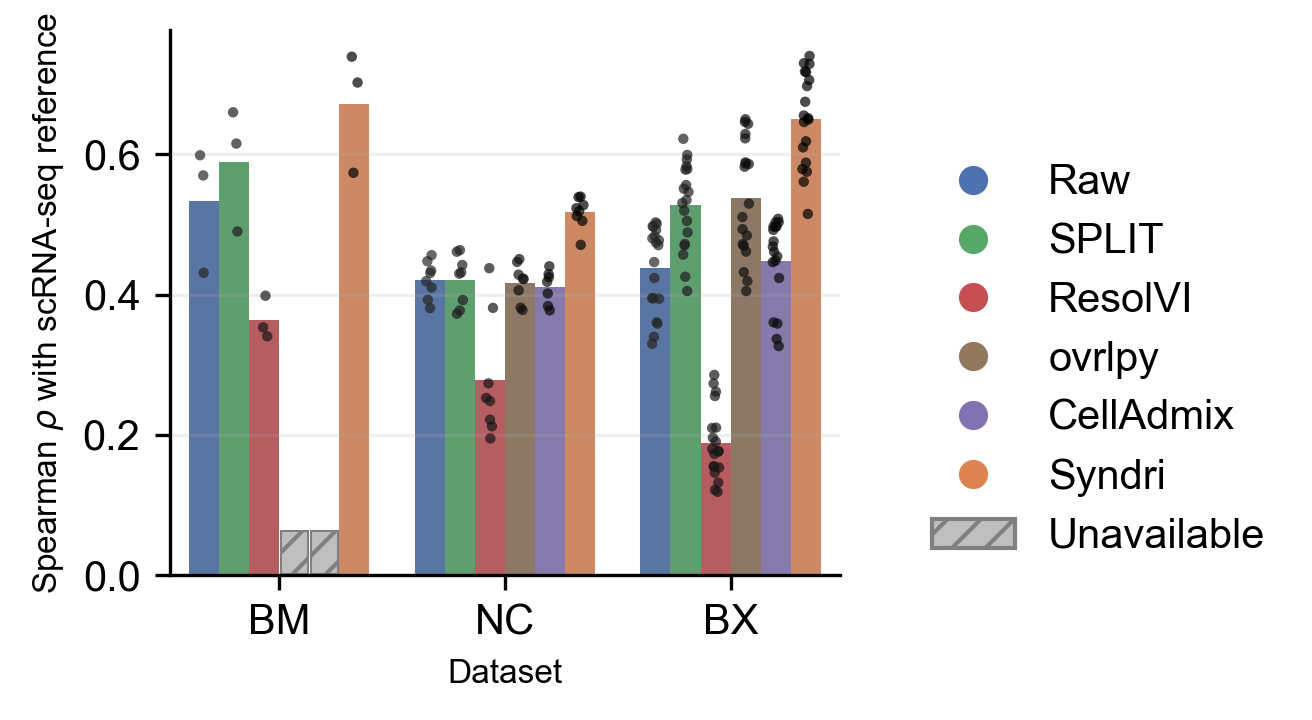

In [14]:
# Combined dataset-by-method barplot with one slice-level point per observation,
# matching the cell-type separation summary in AllDatasetMetricsSimplified.ipynb.
DATASET_ALIASES = {
    'agingbrain_merfish': 'AM',
    'brain_merfish': 'BM',
    'nsclc_cosmx': 'NC',
    'breast_xenium': 'BX',
}
plot_order = [DATASET_ALIASES[dataset] for dataset in DATASET_TITLES]
plot_data = (
    wide.reset_index()
    .melt(id_vars=['dataset', 'slice'], var_name='method', value_name='spearman_rho')
    .dropna(subset=['spearman_rho'])
    .assign(dataset_alias=lambda frame: frame['dataset'].map(DATASET_ALIASES))
)
fig, ax = plt.subplots(figsize=(3.0, 2.5), dpi=300)
sns.barplot(
    data=plot_data, x='dataset_alias', y='spearman_rho', hue='method',
    order=plot_order, hue_order=METHOD_ORDER, dodge=True,
    palette=palette, legend=False, errorbar=None, ax=ax,
)
sns.stripplot(
    data=plot_data, x='dataset_alias', y='spearman_rho', hue='method',
    order=plot_order, hue_order=METHOD_ORDER, dodge=True,
    color='black', size=2.5, alpha=0.7, legend=False, jitter=True, ax=ax,
)

# Hatched slots show unavailable dataset-method combinations.
present = set(zip(
    plot_data.loc[plot_data['spearman_rho'].notna(), 'dataset_alias'],
    plot_data.loc[plot_data['spearman_rho'].notna(), 'method'],
))
ymin, ymax = ax.get_ylim()
slot_width = 0.8 / len(METHOD_ORDER)
for dataset_index, dataset in enumerate(plot_order):
    for method_index, method in enumerate(METHOD_ORDER):
        if (dataset, method) in present:
            continue
        center = dataset_index - 0.4 + (method_index + 0.5) * slot_width
        ax.bar(
            center, 0.08 * (ymax - ymin), width=0.9 * slot_width,
            bottom=0.001, color='0.75', edgecolor='0.5',
            hatch='///', linewidth=0.5, zorder=2,
        )
ax.set_ylim(ymin, ymax)
ax.set_xlabel('Dataset',fontsize=8)
ax.set_ylabel(r'Spearman $\rho$ with scRNA-seq reference',fontsize=8)
ax.set_xticks(range(len(plot_order)), labels=plot_order)
ax.grid(axis='x', visible=False)
ax.grid(axis='y', alpha=0.2)
ax.margins(x=0.03)
sns.despine(ax=ax)

legend_handles = [
    plt.Line2D(
        [0], [0], marker='o', linestyle='', markersize=6,
        markerfacecolor=palette[method], markeredgecolor=palette[method],
        label=method,
    )
    for method in METHOD_ORDER
]
legend_handles.append(
    plt.Rectangle((0, 0), 1, 1, facecolor='0.75', edgecolor='0.5',
                  hatch='///', label='Unavailable')
)
fig.legend(handles=legend_handles, loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'SuppFig2_var.svg',bbox_inches='tight')
plt.show()


### Paired Wilcoxon tests by dataset

In [8]:
paired_summaries = []
for dataset in DATASET_TITLES:
    if dataset not in wide.index.get_level_values("dataset"):
        continue
    dataset_wide = wide.loc[dataset]
    for method in METHOD_ORDER:
        if method == 'Syndri' or method not in dataset_wide:
            continue
        paired = dataset_wide[['Syndri', method]].dropna()
        delta = paired['Syndri'] - paired[method]
        paired_summaries.append({
            'dataset': dataset, 'comparison': f'Syndri vs {method}',
            'n_slices': len(paired), 'median_delta_rho': delta.median(),
            'mean_delta_rho': delta.mean(),
            'iqr_low': delta.quantile(0.25), 'iqr_high': delta.quantile(0.75),
            'wilcoxon_p': wilcoxon(delta).pvalue if len(paired) > 1 and (delta != 0).any() else np.nan,
        })
display(pd.DataFrame(paired_summaries))

,dataset,comparison,n_slices,median_delta_rho,mean_delta_rho,iqr_low,iqr_high,wilcoxon_p
0,agingbrain_merfish,Syndri vs Raw,12,0.007946,0.011145,0.003654,0.020719,0.020996
1,agingbrain_merfish,Syndri vs SPLIT,12,-0.051125,-0.055075,-0.061999,-0.046393,0.000488
2,agingbrain_merfish,Syndri vs ResolVI,12,0.143614,0.148760,0.101083,0.191074,0.000488
3,agingbrain_merfish,Syndri vs ovrlpy,0,NaN,NaN,NaN,NaN,NaN
4,agingbrain_merfish,Syndri vs CellAdmix,0,NaN,NaN,NaN,NaN,NaN
5,brain_merfish,Syndri vs Raw,3,0.140540,0.138567,0.136549,0.141572,0.250000
6,brain_merfish,Syndri vs SPLIT,3,0.083684,0.083332,0.081476,0.085364,0.250000
7,brain_merfish,Syndri vs ResolVI,3,0.340918,0.307746,0.287034,0.345044,0.250000
8,brain_merfish,Syndri vs ovrlpy,0,NaN,NaN,NaN,NaN,NaN
9,brain_merfish,Syndri vs CellAdmix,0,NaN,NaN,NaN,NaN,NaN


In [9]:
# Persist cell-type-level variance concordance for the cross-domain rank summary.
VARIANCE_CONCORDANCE_PATH = PROJECT / 'context_analysis/results/variance_preservation_slice_concordance.csv'
VARIANCE_CONCORDANCE_PATH.parent.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(VARIANCE_CONCORDANCE_PATH, index=False)
print(f'Saved variance concordance: {VARIANCE_CONCORDANCE_PATH}')

Saved variance concordance: /home/jwinchel/Syndri/context_analysis/results/variance_preservation_slice_concordance.csv
